# Import Libraries

In [90]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

# **1. Load Dataset - Data**

In [5]:
df = pd.read_csv('/diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


## Plot Variables

*   **Pregnancies** : Εγκυμοσύνες που έχει περάσει η ασθενής.
*   **Glucose** : Συγκέντρωση γλυκόζης του ασθενούς.
*   **BloodPressure** : Αρτηριακή πίεση
*   **SkinThickness** : Πάχος του δέρματος
*   **Insulin** : Τιμή ινσουλίνης.
*   **BMI** : Δείκτης μάζας σώματος.
*   **DiabetesPedigreeFunction** : Μέτρηση κληρονομικής προδιάθεσης.
*   **Age** : Ηλικία ασθενούς
*   **Outcome** : 1 = o ασθενής έχει διαβήτη, 0 = ο ασθενής δεν έχει διαβήτη







##Μέση Τιμή, Τυπική Απόκλιση, Ελάχιστη και Μέγιστη τιμή μεταβλητών


In [7]:
df.describe().loc[['mean', 'std', 'min', 'max']].round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


##Ιστογράμματα Χαρακτηριστικών

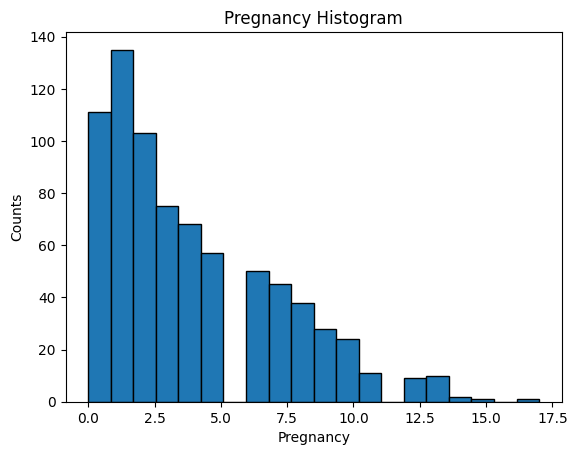

In [11]:
df['Pregnancies'].hist(bins=20, edgecolor='black')
plt.title('Pregnancy Histogram')
plt.xlabel('Pregnancy')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

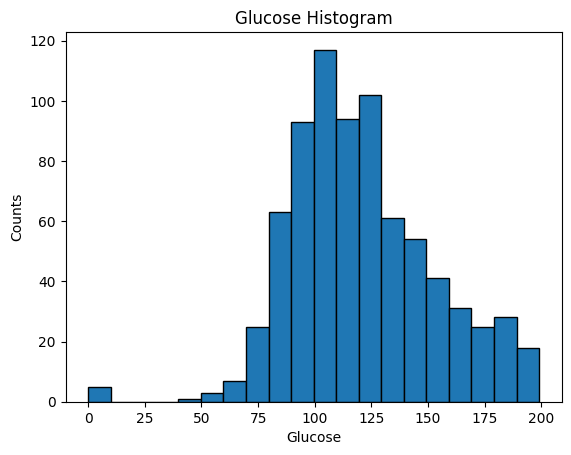

In [10]:
df['Glucose'].hist(bins=20, edgecolor='black')
plt.title('Glucose Histogram')
plt.xlabel('Glucose')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

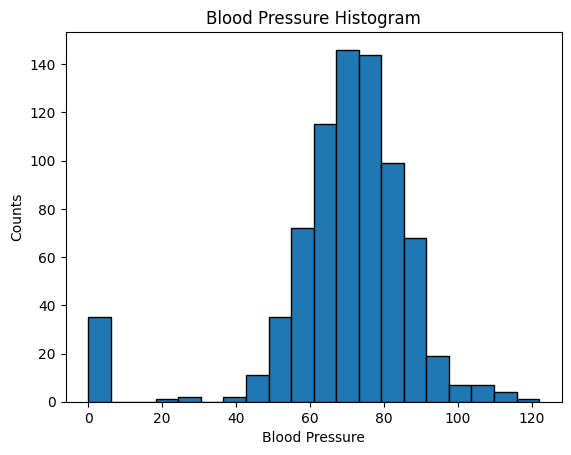

In [12]:
df['BloodPressure'].hist(bins=20, edgecolor='black')
plt.title('Blood Pressure Histogram')
plt.xlabel('Blood Pressure')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

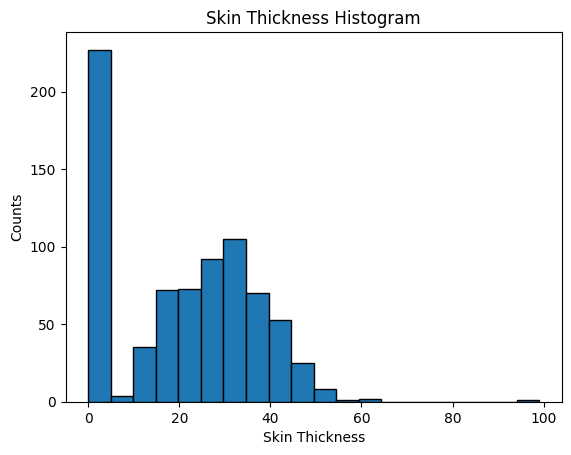

In [13]:
df['SkinThickness'].hist(bins=20, edgecolor='black')
plt.title('Skin Thickness Histogram')
plt.xlabel('Skin Thickness')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

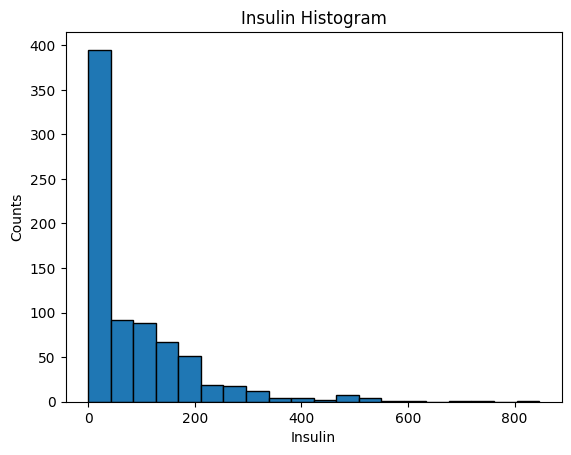

In [9]:
df['Insulin'].hist(bins=20, edgecolor='black')
plt.title('Insulin Histogram')
plt.xlabel('Insulin')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

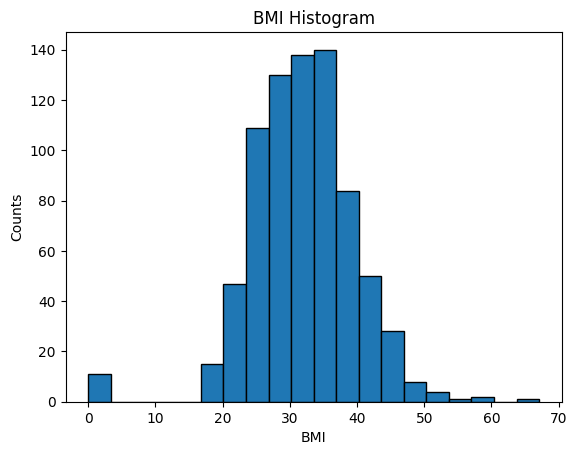

In [14]:
df['BMI'].hist(bins=20, edgecolor='black')
plt.title('BMI Histogram')
plt.xlabel('BMI')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

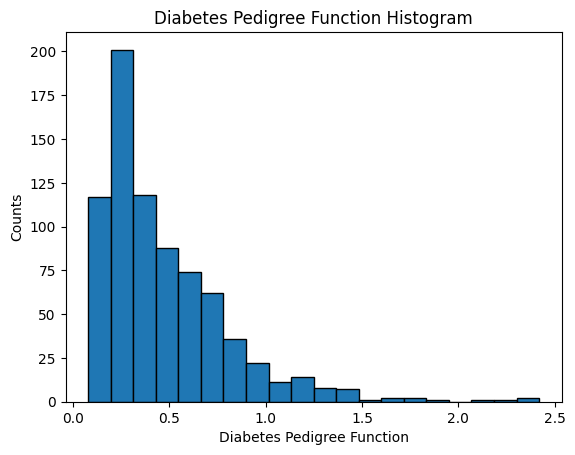

In [15]:
df['DiabetesPedigreeFunction'].hist(bins=20, edgecolor='black')
plt.title('Diabetes Pedigree Function Histogram')
plt.xlabel('Diabetes Pedigree Function')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

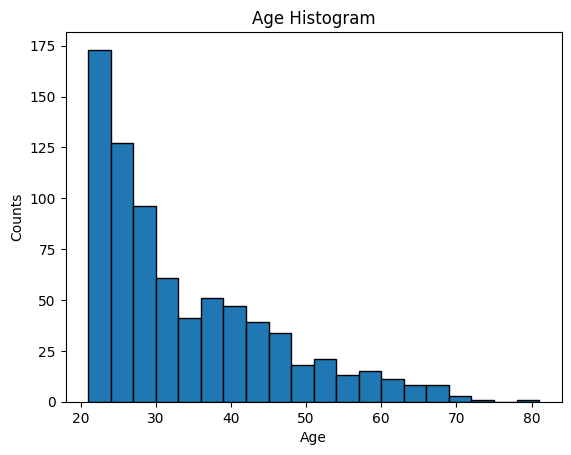

In [16]:
df['Age'].hist(bins=20, edgecolor='black')
plt.title('Age Histogram')
plt.xlabel('Age')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

##Ραβδόγραμμα outcome

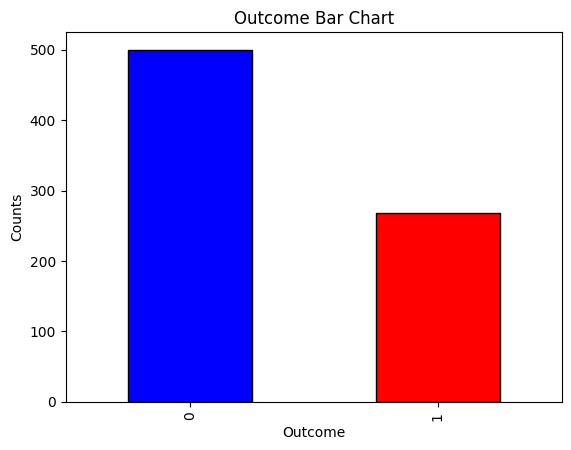

In [28]:
df['Outcome'].value_counts().plot(kind='bar', color=['blue','red'], edgecolor='black')
plt.title('Outcome Bar Char')
plt.xlabel('Outcome')
plt.ylabel('Counts')
plt.grid(False)

# **2. Numpy Arrays and Train - Test Datasets**

##Διαχωρισμός Train - Validation Dataset

In [34]:
input_df = df.drop(columns=['Outcome'])
targets_df = df['Outcome']

x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape

((768, 8), (768,))

In [35]:
seed = 0
test_size = 0.3

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((537, 8), (537,), (231, 8), (231,))

In [70]:
print(f'Number of training samples: {x_train.shape[0]}')
print(f'Number of test samples: {x_test.shape[0]}')

Number of training samples: 537
Number of test samples: 231


# **3. Logistic Regression**

In [71]:
model = LogisticRegression(max_iter=5000, random_state=seed)

## Train model on training set

In [72]:
model.fit(x_train, y_train)

LogisticRegression(max_iter=5000, random_state=0)

## Evaluate Model on train set

In [44]:
y_pred = model.predict(x_train)
y_pred

array([1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1,
       0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1,
       0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1,
       0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,

In [46]:
accuracy = accuracy_score(y_train, y_pred)
accuracy_percentage = round(accuracy*100, 2)

print(f'The accuracy of the model is: {accuracy_percentage}%')

The accuracy of the model is: 76.54%


## Evaluate Model on test set

In [48]:
y_pred = model.predict(x_test)
y_pred

array([1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0])

In [49]:
accuracy = accuracy_score(y_test, y_pred)
accuracy_percentage = round(accuracy*100, 2)

print(f'The accuracy of the model is: {accuracy_percentage}%')

The accuracy of the model is: 77.92%


## Παρατηρήσεις

Στα dataset μας έχουμε : 76.54% ακρίβεια στο train set και 77.92% στο test set. Η διαφορά είναι μικρή, με του test set να είναι ελάχιστα μεγαλύτερη. Άρα, το μοντέλο ανταποκρίνεται καλά σε νέα δεδομένα (χωρίς δηλαδή να κάνει overfitting). Τυχαία, τα δεδομένα του test set ήταν πιο κατάλληλα (μπόρεσε το μοντέλο να τα εντοπίσει πιο εύκολα) και εκεί οφείλεται ότι έχει καλύτερη ακρίβεια αυτό το set.

# **4. Σχέση γλυκόζης και διαβήτη**

Υπολογίζουμε τον μέσο όρο γλυκόζης για τους ασθενείς με ( outcome = 1) και χωρίς (outcome = 0) διαβήτη.

In [65]:
df.groupby('Outcome')['Glucose'].mean()

,Glucose
Outcome,
0,109.980000
1,141.257463


Στη συνέχεια, εφόσον η γλυκόζη ατόμων με διαβήτη ειναι μεγαλύτερη του 140, χωρίζουμε τους ασθενείς σε ομάδες με γλυκόζη <= 140 και >140 και βρίσκουμε τι ποσοστό κάθε ομάδας έχει διαβήτη.

In [66]:
GlucoseH = df[df['Glucose']>140]['Outcome'].mean() * 100
GlucoseL = df[df['Glucose']<=140]['Outcome'].mean() * 100

print(f'Ποσοστό με διαβήτη και υψηλή γλυκόζη: {GlucoseH.round(2)} %')
print(f'Ποσοστό με διαβήτη και χαμηλή γλυκόζη: {GlucoseL.round(2)} %')

Ποσοστό με διαβήτη και υψηλή γλυκόζη: 68.75 %
Ποσοστό με διαβήτη και χαμηλή γλυκόζη: 23.61 %


Άρα, η πιθανότητα να έχει κανείς διαβήτη με υψηλή γλυκόζη είναι σχεδόν τριπλάσια.

# **5. Ακρίβεια ανά ομάδα ηλικιών (test set)**




Παίρνουμε τις προβλέψεις του μοντέλου απο το test set για την ηλικία (Age είναι η στήλη 7) κάθε ασθενούς.

In [86]:
y_pred= model.predict(x_test)
age = x_test[:, 7]

Δημιουργώ τις ηλικιακές ομάδες που με ενδιαφέρουν

In [87]:
group1 = age <= 25                  # 0 έως 25
group2 = (age > 25) & (age <= 50)   # 25 έως 50
group3 = age > 50                   # πάνω από 50

print('Ασθενείς 0-25:', group1.sum())
print('Ασθενείς 25-50:', group2.sum())
print('Ασθενείς >50:', group3.sum())

Ασθενείς 0-25: 90
Ασθενείς 25-50: 120
Ασθενείς >50: 21


Με `y_test[group1]` κρατάμε μόνο τις σωστές απαντήσεις των ασθενών της ομάδας 1, και με `y_pred[group1]` μόνο τις προβλέψεις του μοντέλου γι' αυτούς. Το `accuracy_score` τις συγκρίνει.

In [88]:
acc1 = accuracy_score(y_test[group1], y_pred[group1]) * 100
acc2 = accuracy_score(y_test[group2], y_pred[group2]) * 100
acc3 = accuracy_score(y_test[group3], y_pred[group3]) * 100

print(f'Ακρίβεια 0-25: {round(acc1, 2)} % ')
print(f'Ακρίβεια 25-50: {round(acc2, 2)} % ')
print(f'Ακρίβεια >50: {round(acc3, 2)} % ')

Ακρίβεια 0-25: 85.56 % 
Ακρίβεια 25-50: 70.0 % 
Ακρίβεια >50: 90.48 % 


Ραβδόγραμμα

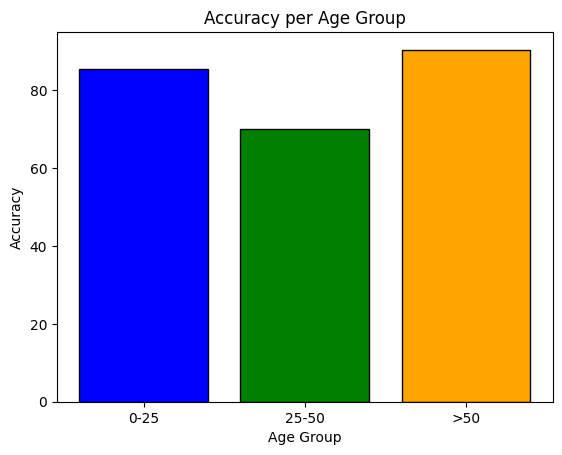

In [89]:
groups = ['0-25', '25-50', '>50']
accuracies = [acc1, acc2, acc3]

plt.bar(groups, accuracies, color = ['blue' , 'green', 'orange'] , edgecolor='black' )
plt.title('Accuracy per Age Group')
plt.xlabel('Age Group')
plt.ylabel('Accuracy')
plt.grid(False)

Στο ραβδόγραμμα φαίνεται η διαφορά στην ακρίβεια η οποία είναι χαμηλότερη στην ομάδα 25-50. Το ποσοστό των 0-25 που έχουν διαβήτη είναι μικρό και επομένως εύκολα προβλέπεται ότι δεν έχουν διαβήτη. Στην ομάδα 25-50 είναι εκεί που τα δεδομένα είναι πιο ισότιμα κατανεμημένα άρα είναι και πιο δύσκολο για το μοντέλο να τα προβλέψει. Τέλος, τα δεδομένα για ηλικίες μεγαλύτερες των 50 είναι πολύ λίγα σε σχέση με τις υπόλοιπες ηλικίες.

# **6. Χειρότερο Λάθος**

Υπάρχουν 2 είδη λαθών:
Ο ασθενής να έχει διαβήτη και να μην ανιχνευθεί (False Negative) ή ο ασθενής να μην έχει διαβήτη και να βγει λανθασμένα ότι έχει (False Positive). Χειρότερο για την εφαρμογή μας είναι το False Negative, καθώς μπορεί να μην υπάρξει ξανά κάποια εξέταση και να μείνει ο ασθενής χωρίς διάγνωση.